In [2]:
import requests
import matplotlib.pyplot as plt

url = "https://archive-api.open-meteo.com/v1/archive"

parametros = {
"latitude": 37.7796,
"longitude": -3.7849,
"start_date": "2025-01-01",
"end_date": "2025-01-31",
"daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min",
"timezone": "Europe/Madrid",
}

respuesta = requests.get(url, params=parametros, timeout=30)
respuesta.raise_for_status()
datos = respuesta.json()
diarios = datos["daily"]

# 9. Representa los resultados #

### Gráfico de líneas: evolución de las temperaturas ###

**Explicación:** gráfico de líneas con la evolución diaria de la temperatura media, máxima y mínima en Jaén durante enero de 2025. En el eje X están los días del mes (1 a 31) y en el eje Y la temperatura en °C. Cada línea tiene un color distinto y la leyenda indica cuál es cada una.

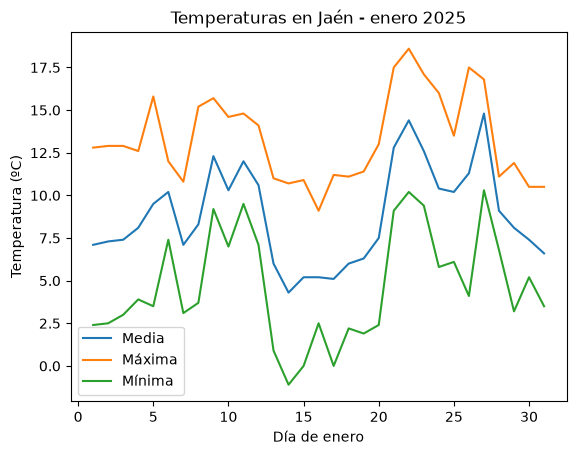

In [3]:
dias = list(range(1, len(diarios["time"]) + 1))

plt.plot(dias, diarios["temperature_2m_mean"], label ="Media")
plt.plot(dias, diarios["temperature_2m_max"], label ="Máxima")
plt.plot(dias, diarios["temperature_2m_min"], label="Mínima")
plt.title("Temperaturas en Jaén - enero 2025")
plt.xlabel("Día de enero")
plt.ylabel("Temperatura (ºC)")
plt.legend()
plt.savefig("evolucion_enero_2025.png")
plt.show()

**Conclusiones:**
- Las tres líneas suben y bajan a la vez: cuando un día es más cálido, lo son su media, su máxima y su mínima.
- Entre los días 13 y 20 hubo una racha fría: la mínima bajó de 0 °C (-1,1 °C el día 14).
- La media tuvo sus picos más altos los días 22 y 27 (14,8 °C).
- La línea de las mínimas es la que más sube y baja (desviación típica 3,17): las noches cambian más que los días.

### Gráfico de barras: medias semanales ###
**Explicación:** para cada semana de enero calculo la media de las temperaturas medias, máximas y mínimas, y las dibujo como tres barras juntas. La semana 5 solo tiene 3 días (29, 30 y 31).

Medias: [8.1, 9.1, 6.9, 11.8, 7.4]
Máximas: [12.8, 13.7, 12.0, 15.8, 11.0]
Mínimas: [3.7, 5.2, 2.6, 7.5, 4.0]


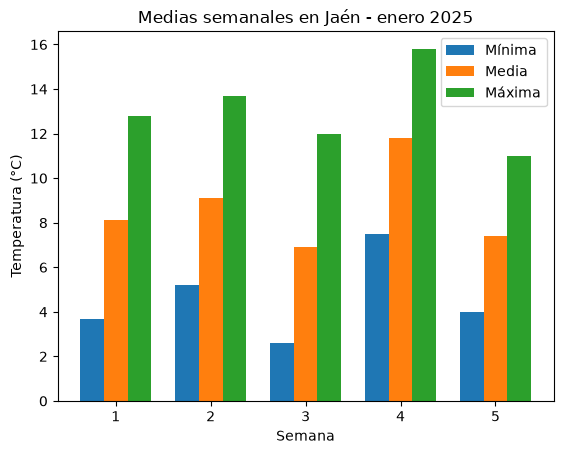

In [4]:
# Función que divide una lista en trozos de 7 días y devuelve la media de cada trozo
def medias_semanales(lista):
    resultado = []
    for i in range(0, len(lista), 7):
        semana = lista[i:i+7]
        resultado.append(round(sum(semana) / len(semana), 1))
    return resultado

media_sem = medias_semanales(diarios["temperature_2m_mean"])
max_sem = medias_semanales(diarios["temperature_2m_max"])
min_sem = medias_semanales(diarios["temperature_2m_min"])
print("Medias:", media_sem)
print("Máximas:", max_sem)
print("Mínimas:", min_sem)

# Cada semana tiene 3 barras: muevo la mínima 0.25 a la izquierda y la máxima 0.25 a la derecha
semanas = [1, 2, 3, 4, 5]
plt.bar([s - 0.25 for s in semanas], min_sem, width=0.25, label="Mínima")
plt.bar(semanas, media_sem, width=0.25, label="Media")
plt.bar([s + 0.25 for s in semanas], max_sem, width=0.25, label="Máxima")
plt.title("Medias semanales en Jaén - enero 2025")
plt.xlabel("Semana")
plt.ylabel("Temperatura (°C)")
plt.xticks(semanas)
plt.legend()
plt.savefig("barras_semanales.png")
plt.show()

**Conclusiones:**
- La semana 4 fue la más templada en las tres medidas (media 11,8 °C, máxima 15,8 °C y mínima 7,5 °C).
- La semana 3 fue la más fría en las tres (media 6,9 °C, máxima 12,0 °C y mínima 2,6 °C): coincide con la racha fría de los días 13 a 20.
- Cada semana hay entre 7 y 9,4 grados de diferencia entre la máxima y la mínima. La semana 5 tiene menos diferencia, pero solo cuenta 3 días.
- Aunque hubo un día con -1,1 °C, ninguna semana tiene la mínima media por debajo de 0 °C: el resto de días de esa semana compensan.

### Gráfico de barras: amplitud térmica diaria ###
**Explicación:** la amplitud térmica de cada día es la máxima menos la mínima, es decir, cuánto cambió la temperatura entre la noche y el día. Dibujo una barra por día.

Amplitudes: [10.4, 10.4, 9.9, 8.7, 12.3, 4.6, 7.7, 11.5, 6.5, 7.6, 5.3, 7.0, 10.1, 11.8, 10.9, 6.6, 11.2, 8.9, 9.5, 10.6, 8.4, 8.4, 7.7, 10.2, 7.4, 13.4, 6.5, 4.3, 8.7, 5.3, 7.0]
Mayor amplitud: 13.4 - día 26
Menor amplitud: 4.3 - día 10


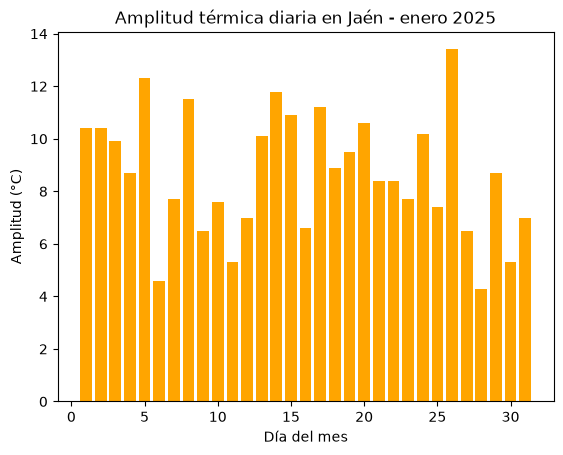

In [5]:
# Amplitud de cada día: máxima - mínima (zip recorre las dos listas a la vez)
amplitudes =[round(mx - mn, 1) for mx, mn in zip(diarios["temperature_2m_max"], diarios["temperature_2m_min"])]
print("Amplitudes:", amplitudes)
print("Mayor amplitud:", max(amplitudes), "- día", amplitudes.index(max(amplitudes)) + 1)
print("Menor amplitud:", min(amplitudes), "- día", amplitudes.index((min(amplitudes)) + 1))

plt.bar(dias, amplitudes, color="orange")
plt.title("Amplitud térmica diaria en Jaén - enero 2025")
plt.xlabel("Día del mes")
plt.ylabel("Amplitud (°C)")
plt.savefig("amplitudes.png")
plt.show()

**Conclusiones:**
- La amplitud térmica cambia mucho de un día a otro: va de 4,3 °C (día 28) a 13,4 °C (día 26).
- La mayoría de los días la diferencia entre el día y la noche está entre 7 y 11 °C.
- Los días con poca amplitud (6, 11 y 28) seguramente fueron nublados o lluviosos: las nubes impiden que haga tanto calor de día y tanto frío de noche.
- Los días 26 y 28 están muy cerca y son muy distintos: el tiempo cambió mucho en esos días.